# **Setup**

In [ ]:
#| label: setup_packages_paths
#| code-fold: true
#| code-summary: "Setup: Imports and Reference File Paths"
#| output: false

# -------- data --------
import pyranges as pr
import pyfaidx                                  # FASTA indexing backend used by pr.get_sequence()
import pandas as pd
import numpy as np

# -------- cmd / files / strings --------
import os
import re
import subprocess
import tempfile
from pathlib import Path
from datetime import datetime

# -------- graph --------
import matplotlib.pyplot as plt
from PIL import Image                          # reads the CIS-BP logo PNGs

# -------- display --------
from IPython.display import display, Markdown, HTML
import session_info

# -------- Setting the Path for the necessary files -------- #
# Everything is derived from PROJECT, so moving the project only changes one line.
# str() is used for the reference files because they are handed to pyranges/pyfaidx.

PROJECT = Path("/srv/ext_home/ssalazar/projects/GIMM_projects/DNA_018_PromotorSeq_MotifFinder")
DATA    = PROJECT / "Data"
RESULTS = PROJECT / "Results"
RESULTS.mkdir(parents=True, exist_ok=True)

REFSEQ  = DATA / "ncbi_dataset_RefSeq_GCF_000001635.27"
GTF_v27 = str(REFSEQ / "genomic.gff")
FA_v27  = str(REFSEQ / "GCF_000001635.27_GRCm39_genomic.fna")

# written by the sequence-extraction cell, read back by every scan
PROMOTER_FASTA = RESULTS / "promoters_sequences.fasta"
PROMOTER_FASTA_5kb = RESULTS / "promoters_sequences_5kb.fasta"



In [ ]:
#| label: gtf_import
#| code-fold: true
#| code-summary: "Import and Filter Reference GTF"
#| output: false
# -------- Reference GTF -------- #
gtf = pr.read_gff3(GTF_v27)                           # Import the GTF file, which has all the information necessary to extract the coordinates. Keep all attributes in single string
gtf_canonical = gtf[(gtf.Feature == "mRNA") & 
                     gtf.tag.str.contains("RefSeq Select", na=False)] 
   # Filter to include only transcripts that contain the tag "RefSeq Select" (curated to canonical transcripts)

In [ ]:
#| label: gene_subset
#| code-fold: true
#| code-summary: "Select Canonical Transcripts for Genes of Interest"
#| output: asis
# List of genes of interest

#the gene name needs to be have a format with the first letter only in Caps to be found
genes = ["Spic", "Nfe2l2", "Bach1", "Blvra", "Hmox1",  "Vcam1", "Slc40a1", "Gsr", "Slc7a11", "Gclc", "Cat", "Gpx4", "Gclm", "Gss", "Txnrd1",  "Fth1", "Nfs1", "Cisd1", 
         "Aifm2", "Acsl4", "Acsl1", "Lpcat3", "G6pdx", "Pgd", "Me1", "Idh1", "Nox1", "Elovl7", "Ido1", "Alas1", "Dhodh", "Acsl3", "Scd1", "Scd5", "Nqo1"]             

# NCBI RefSeq GFF3 uses "gene", not "gene_name" -- confirm via gtf_canonical.columns.tolist()
# before trusting this line if it comes back empty.
gtf_sub = gtf_canonical[gtf_canonical.gene.isin(genes)]
 
found = set(gtf_sub.df["gene"])
missing = set(genes) - found
 
print(f"{len(found)}/{len(set(genes))} genes found")

if missing:
    print(f"Missing: {sorted(missing)}")

print()
print(f"Are there duplicated values: {gtf_sub.df['gene'].duplicated().any()}")

In [ ]:
#| label: gtf_sub_preview
#| code-fold: true
#| code-summary: "Selected Transcript Coordinates"
#| output: asis
gtf_sub[['Chromosome', 'gene', 'transcript_id', 'Source', 'Feature', 'Start', 'End', 'Strand']]    # Inspect the selected canonical transcripts (one per gene of interest)

In [ ]:
#| label: promoter_coords
#| code-fold: true
#| code-summary: "Compute 2 kb Promoter Coordinates"
#| output: true

# five_end(): collapses each interval to its single TSS coordinate (strand-aware --
#             gene Start on +, gene End on -), giving a 1bp interval at the TSS.
# .slack({"5": 2000, "3": 200}): extends that TSS point strand-aware:
#             2000bp toward the 5' side (upstream) and 200bp toward the 3' side
#             (downstream), so the result is your -2000/+200 promoter window
#             regardless of which genomic strand the gene is on.
prom_2kb = gtf_sub.five_end().slack({"5": 2000, "3": 200}) 
prom_2kb[['gene','transcript_id','Start', 'End', 'Strand']]                            

In [6]:
#| label: extract_sequences
#| code-fold: true
#| code-summary: "Extract Promoter Sequences from Reference"
#| output: false

seqs_2kb = pr.get_sequence(prom_2kb, path=FA_v27)                        # Based on the coordinates identified before, we get the sequences from the reference genome
#get_sequence is also strand-aware and reverse-complements the minus strand

df_2kb                 = seqs_2kb.to_frame(name="DNA_Sequence")   # Convert the extracted sequences into a dataframe
df_2kb["Gene_Name"]    = prom_2kb.df['gene']                 # Attach gene names for use in the FASTA headers
df_2kb["TranscriptID"] = prom_2kb.df["transcript_id"]             # Attach transcript IDs for use in the FASTA headers

with open(PROMOTER_FASTA, "w") as file:
    for index, row in df_2kb.iterrows():
        # Combine your metadata into a single header line
        header = f">{row['Gene_Name']}|{row['TranscriptID']}"
        
        # Write the header and the sequence
        file.write(f"{header}\n")
        file.write(f"{row['DNA_Sequence']}\n")

In [7]:
#| label: rsat_setup
#| code-fold: true
#| code-summary: "Setup: paths and scan parameters"
#| output: false
 
# paths and variables
 
SCAN_DIR = RESULTS / "matrix_scan"
SCAN_DIR.mkdir(parents=True, exist_ok=True)
RSAT_ENV = Path("/srv/ext_home/ssalazar/.conda/envs/rsat")
 
MARKOV_ORDER = 1        # background order; oligo length k = order + 1
PVAL         = 1e-4
TSS_OFFSET   = 201      # -origin end places the TSS at -201
 
# rsat is a Perl script: its env's bin must lead PATH, or the shebang picks base's perl
ENV = os.environ | {"PATH": f"{RSAT_ENV / 'bin'}{os.pathsep}{os.environ['PATH']}",
                     "RSAT": str(RSAT_ENV / 'share' / 'rsat'),
                     "CONDA_PREFIX": str(RSAT_ENV)}
 
 
def rsat(tool, *args):
    # some tools report errors on stdout while exiting 0
    cmd = [str(RSAT_ENV / "bin" / "rsat"), tool, *map(str, args)]
    p = subprocess.run(cmd, capture_output=True, text=True, env=ENV)
    out = p.stderr + p.stdout
    if p.returncode or re.search(r"^Error", out, re.M):
        raise RuntimeError(" ".join(cmd) + "\n" + out)
    return out
 
 
def read_fasta(path):
    # [(header, sequence), ...], headers keep their '>'
    # used for counting/subsetting only, so no Biopython dependency;
    # `cur is not None` (not `cur`) so a header right after another header
    # doesn't swallow the next record's lines
    recs, cur = [], None
    for line in Path(path).read_text().splitlines():
        if line.startswith(">"):
            cur = [line, []]
            recs.append(cur)
        elif cur is not None:
            cur[1].append(line.strip())
    return [(h, "".join(s)) for h, s in recs]
 
 

In [ ]:
#| label: tf_matrices
#| code-fold: true
#| code-summary: "transcription factor matrices"
#| output: asis
 
CISBP = DATA / "Mus_musculus_2026_09_17_11_49_am_CISBP"
 
# motif accession -> name to use in the ft_name column of the scan
# looked up once in TF_Information.txt, then hard-coded here
MOTIFS = {"M03221_3.10": "Spic",
          "M09222_3.10": "Nfe2l2_1",
          "M10174_3.10": "Nfe2l2_2",
          "M10181_3.10": "Bach1"}
 
# color dictionary for consistency across plots (npg / Nature Publishing Group palette)
MOTIF_COLORS = {"Spic":     "#E64B35",
                 "Nfe2l2_1": "#4DBBD5",
                 "Nfe2l2_2": "#00A087",
                 "Bach1":    "#3C5488"}

blocks = []
for acc, label in MOTIFS.items():
    m = pd.read_csv(CISBP / "pwms_all_motifs" / f"{acc}.txt", sep="\t")
 
    # CIS-BP gives probabilities (rows sum to 1); x100 makes them count-like, so
    # matrix-scan's -pseudo 1 stays a small correction instead of half the column
    rows = [f"{i:02d}\t" + "\t".join(f"{v * 100:.4f}" for v in r)
            for i, r in enumerate(m[["A", "C", "G", "T"]].values, start=1)]
 
    blocks.append(f"AC  {acc}\nXX\nID  {label}\nXX\nDE  {label}\n"
                   "P0\tA\tC\tG\tT\n" + "\n".join(rows) + "\nXX\n//\n")
    print(f"  {acc:<14} {len(m)} bp -> {label}")

    # Show the CIS-BP logo of the matrix actually scanned, both orientations, so the
    # report records what each matrix looks like and not only its accession.
    ifw  = Image.open(CISBP / "logos_used_motifs" / f"{acc}_fwd.png")
    irev = Image.open(CISBP / "logos_used_motifs" / f"{acc}_rev.png")

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(ifw)
    axes[0].set_title(f"{label} ({acc}) - forward")
    axes[0].axis("off")
    axes[1].imshow(irev)
    axes[1].set_title(f"{label} ({acc}) - reverse")
    axes[1].axis("off")
    plt.tight_layout()
    fig.savefig(SCAN_DIR / f"motif_logo_{label}.svg", format="svg", bbox_inches="tight")
    plt.show()
 
MATRIX = SCAN_DIR / "motif_matrices_SpiC_Nfe2l2_Bach1.tf"
MATRIX.write_text("".join(blocks))
print(f"\n{len(blocks)} matrices saved in {MATRIX.name}")

# Functions


In [9]:
#| label: rsat_scan
#| code-fold: true
#| code-summary: "Motif scan function"
#| output: false
 
def scan(motifs, genes=None, pval=PVAL, name=None, bg_from="input", MATRIX = MATRIX, FASTA=None):
    # motifs: list of ft_name labels, e.g. ['Spic', 'Bach1']
    # genes: list of gene names; None scans all promoters
    # only the .ft.txt is kept

    out = SCAN_DIR / f"scanmotif_{name}.ft"

    # matrix subset, promoter subset and background model are RSAT inputs, so they're
    # written to a temp dir removed on return; still recoverable from the ';' header of
    # the .ft.txt, which records the matrix, pseudo-counts and residue probabilities
    with tempfile.TemporaryDirectory() as tmp:
        tmp = Path(tmp)
 
        # requested matrices only, from motif_matrices_SpiC_Nfe2l2_Bach1.tf
        blocks = [b.strip() + "\n//\n" for b in MATRIX.read_text().split("//")
                  if (m := re.search(r"^ID\s+(\S+)\s*$", b, re.M))
                  and m.group(1) in motifs]
        assert len(blocks) == len(motifs), f"matrix not found, wanted {motifs}"
        mat = tmp / "matrices.tf"
        mat.write_text("".join(blocks))
 
        # requested promoters only; genes=None keeps all
        recs = [(i, s) for i, s in read_fasta(FASTA)
                if not genes or any(g.lower() in i.lower() for g in genes)]
        assert recs, f"no promoter matched {genes}"
        seqs = tmp / "promoters.fasta"
        seqs.write_text("".join(f">{i}\n{s}\n" for i, s in recs))
 
        # background is always estimated from the FULL promoter set, never the gene
        # -bginput / create-background-model fail in this build (rsat-core 2025.04.04,
        # bioconda) at every Markov order ("the sum must be strictly positive", then a
        # division by zero in RSAT/matrix.pm), so the model is estimated with
        # oligo-analysis and passed via -bgfile instead: same estimator, same sequences.
        # -1str matches the web run, whose residue probabilities are strand-asymmetric.
        # verified against the web run: 62/63 sites, same 20 promoters, marginals to 3 decimals
        bg = tmp / "bg.tab"
        bg_src = FASTA if bg_from == "all" else seqs
        rsat("oligo-analysis", "-i", bg_src, "-l", MARKOV_ORDER + 1, "-1str",
             "-return", "occ,freq", "-o", bg)
 
        # -origin end keeps positions negative from the sequence end (TSS at -TSS_OFFSET)
        # -2str reports D/R, combined with transcript strand downstream
        # -return limits gives the START_END rows used for promoter extents
        rsat("matrix-scan", "-v", 1,
             "-i", seqs, "-seq_format", "fasta",
             "-m", mat, "-matrix_format", "transfac",
             "-bgfile", bg, "-bg_pseudo", 0.01, "-pseudo", 1,
             "-2str", "-origin", "end", "-n", "score",
             "-return", "limits", "-return", "sites", "-return", "pval",
             "-uth", "pval", pval, "-o", out)
 
    hits = pd.read_csv(out, sep="\t", comment=";").query("ft_type == 'site'")
    hits.attrs["scan_path"] = out
    print(f"{len(recs)} promoters, {len(motifs)} matrices, "
          f"{len(hits)} sites at P < {pval:g}")
   
    return hits

In [10]:
#| label: sitemap_function
#| code-fold: true
#| code-summary: "Site map function"
#| output: false

def sitemap(hits, name=None, pval=PVAL, MOTIF_COLORS = MOTIF_COLORS):
    """Map motif sites along each promoter, positions relative to the TSS.

    hits  the DataFrame returned by scan(); its .attrs['scan_path'] is re-read to
          recover the 'limit' rows, so promoters with no site still get a lane.
    """
    
    path = Path(hits.attrs["scan_path"])
    lim  = (pd.read_csv(path, sep="\t", comment=";").query("ft_type == 'limit'")
              .drop_duplicates("#seq_id").set_index("#seq_id"))

    h = hits.assign(tss_pos=hits[["start", "end"]].mean(axis=1) + TSS_OFFSET,
                    logp=-np.log10(hits["Pval"]))
    ypos   = {s: i for i, s in enumerate(lim.index)}
    colors = {m: MOTIF_COLORS.get(m, "0.4") for m in h["ft_name"].unique()}

    fig, ax = plt.subplots(figsize=(9, 0.33 * len(lim) + 1.5))
    ax.hlines(range(len(lim)), lim["start"] + TSS_OFFSET, lim["end"] + TSS_OFFSET,
              color="0.87", lw=3.5, zorder=1)

    # Size scales with significance from the threshold up; label once per motif,
    # on the direct strand, so the legend shows colour rather than colour x strand.
    for (motif, strand), g in h.groupby(["ft_name", "strand"]):
        ax.scatter(g["tss_pos"], g["#seq_id"].map(ypos),
                   marker="v" if strand == "R" else "^",
                   s=50 + 200 * (g["logp"] + np.log10(pval)) / 3,
                   color=colors[motif], zorder=3, alpha=0.85,
                   edgecolors="white", linewidths=0.4,
                   label=motif if strand == "D" else None)

    ax.axvline(0, color="crimson", lw=1, ls="--", zorder=2)
    ax.text(0, -0.65, " TSS", color="crimson", va="top", fontsize=8)
    ax.set_yticks(range(len(lim)))
    ax.set_yticklabels([s.lstrip(">").split("|")[0] for s in lim.index], fontsize=10)
    ax.set_ylim(-0.7, len(lim) - 0.3); ax.invert_yaxis()
    ax.set_xlabel("position relative to TSS (bp)")
    ax.legend(title=f"motif (P < {pval:g})", fontsize=10, title_fontsize=10,
              markerscale=0.8, loc="upper left", bbox_to_anchor=(1.01, 1),
              frameon=False)
    ax.spines[["top", "right", "left"]].set_visible(False)
    fig.tight_layout(rect=[0, 0, 0.85, 1])

    fig_path = SCAN_DIR / f"sitemap_{name}.svg"
    fig.savefig(fig_path)
  
    return fig

In [12]:
#| label: process_motif_hits
#| code-fold: true
#| code-summary: "Process motif hits"
#| output: false

def process_motif_hits(name, hits_df, gtf_sub):

        # prepare data from RSAT tools
        sites = hits_df[hits_df["ft_type"] == "site"].copy()   # drop the 'limit' (START_END) rows, not significant
        sites[["Gene_Name", "TranscriptID"]] = sites["#seq_id"].str.split("|", expand=True)  # seq_id = Gene_Name|TranscriptID
        sites["Gene_Name"] = sites["Gene_Name"].str.strip('>')

        sites_filtered = sites[['Gene_Name', 'TranscriptID', 'sequence', 'start', 'end', 'strand', 'Pval', 'sig']].copy()
        sites_filtered = sites_filtered.rename(columns={'sequence': 'Motif_Sequence_Found',
                                                        'start':   "start_motif_pos_promoter",   # 1-based TSS base
                                                        'end':     "end_motif_pos_promoter",
                                                        'strand':  "strand_motif"})

        # get transcript metadata + TSS (from five_end(), 1-based, strand dependent), merge in one go
        meta = (gtf_sub.df[["Chromosome", "Strand", "transcript_id"]]
                .rename(columns={"Strand": "Chromosome_Strand", "transcript_id": "TranscriptID"})
                .merge(gtf_sub.five_end().df[["transcript_id", "End"]]
                        .rename(columns={"End": "TSS_chromosomal_localization", "transcript_id": "TranscriptID"}),
                        on="TranscriptID", how="left"))

        sites_filtered = sites_filtered.merge(meta, on="TranscriptID", how="left")

        # transcript-relative edges: 0 = TSS base, + = downstream (origin=end anchor at -201)
        sites_filtered["start_motif_pos_promoter"] += TSS_OFFSET
        sites_filtered["end_motif_pos_promoter"]   += TSS_OFFSET

        # nearest edge: end if upstream, start if downstream, 0 if it straddles the TSS
        sites_filtered["dist_to_TSS"] = np.where(
        sites_filtered["end_motif_pos_promoter"] < 0, sites_filtered["end_motif_pos_promoter"],
        np.where(sites_filtered["start_motif_pos_promoter"] > 0, sites_filtered["start_motif_pos_promoter"], 0),
        )

        # to genome (1-based): + adds, - subtracts (edges swap so start <= end)
        plus = sites_filtered["Chromosome_Strand"].eq("+")
        TSS  = sites_filtered["TSS_chromosomal_localization"]
        start = np.where(plus, TSS + sites_filtered["start_motif_pos_promoter"], TSS - sites_filtered["end_motif_pos_promoter"])
        end   = np.where(plus, TSS + sites_filtered["end_motif_pos_promoter"],   TSS - sites_filtered["start_motif_pos_promoter"])

        sites_filtered["motif_genomic_localization"] = start.astype(int).astype(str) + "-" + end.astype(int).astype(str)
        sites_filtered["motif_genomic_strand"] = np.where(plus == sites_filtered["strand_motif"].eq("D"), "+", "-")

        sites_filtered.drop(columns=["strand_motif"], inplace=True)

        sites_filtered.to_csv(RESULTS / f"motifs_coordinates_{name}.csv", index=False)
        return sites_filtered

## Motifs of SpiC, Nfe2l2 and Bach1 in the assumed SpiC Network

32 promoters, 4 matrices, 93 sites at P < 0.0001


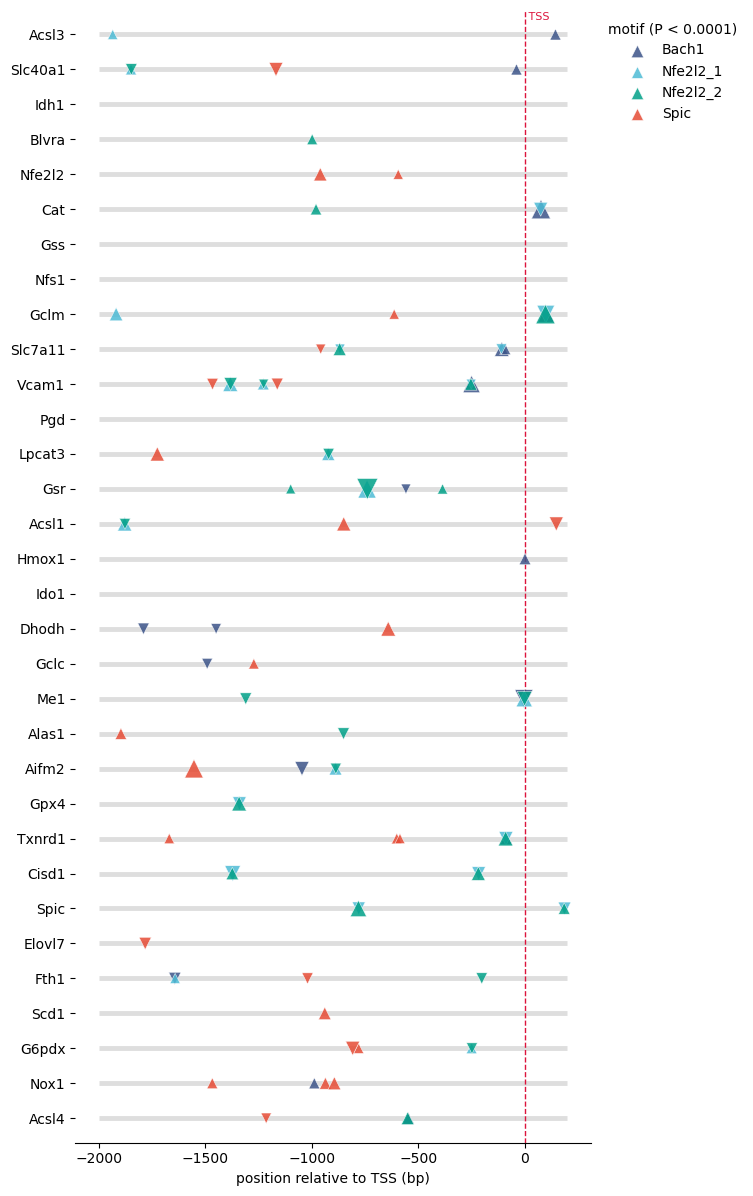

In [30]:
#| label: spicnetwork_alltfs_motifs_map
#| code-fold: true
#| code-summary: "SpiC Network SpiC, Nfe2l2 and Bach1 Motifs Map"
#| output: asis
#| column: page

# All four matrices over the 30 network promoters: the full site inventory.
hits_SpiCnet_allmotifs = scan(["Spic", "Nfe2l2_1", "Nfe2l2_2", "Bach1"], genes=["Spic","Nfe2l2", "Blvra", "Hmox1",  "Vcam1", "Slc40a1", "Gsr", "Slc7a11", "Gclc", "Cat", "Gpx4", "Gclm", "Gss", "Txnrd1",  "Fth1", "Nfs1", "Cisd1", 
         "Aifm2", "Acsl4", "Acsl1", "Lpcat3", "G6pdx", "Pgd", "Me1", "Idh1", "Nox1", "Elovl7", "Ido1", "Alas1", "Dhodh", "Acsl3", "Scd1"], name='SpiC_network_all_TFs', FASTA = PROMOTER_FASTA)             

graph_SpiCnet_allmotifs = sitemap(hits_SpiCnet_allmotifs, name="SpiC_network_all_TFs")

In [31]:
#| label: spicnetwork_alltfs_motifs_table
#| code-fold: true
#| code-summary: "SpiC Network SpiC, Nfe2l2 and Bach1 Motifs Table"
#| output: asis

# Genomic coordinates for the full network inventory.
spicnet_allmotifs_table = process_motif_hits("SpiC_network_all_TFs", hits_SpiCnet_allmotifs, gtf_sub)
spicnet_allmotifs_table

,Gene_Name,TranscriptID,Motif_Sequence_Found,start_motif_pos_promoter,end_motif_pos_promoter,Pval,sig,Chromosome,Chromosome_Strand,TSS_chromosomal_localization,dist_to_TSS,motif_genomic_localization,motif_genomic_strand
0,Acsl3,NM_001033606.3,GTGAGTCATCA,-1939,-1929,0.000091,4.041,NC_000067.7,+,78635600,-1929,78633661-78633671,+
1,Acsl3,NM_001033606.3,AGCTGCGTCAGGGT,138,151,0.000063,4.203,NC_000067.7,+,78635600,138,78635738-78635751,+
2,Slc40a1,NM_016917.2,GTGACTGAGCT,-1853,-1843,0.000067,4.171,NC_000067.7,-,45964754,-1843,45966597-45966607,-
3,Slc40a1,NM_016917.2,CATAGCTCAGTCAC,-1853,-1840,0.000054,4.271,NC_000067.7,-,45964754,-1840,45966594-45966607,+
4,Slc40a1,NM_016917.2,AAAATGGGGTAGTA,-1174,-1161,0.000020,4.689,NC_000067.7,-,45964754,-1161,45965915-45965928,+
...,...,...,...,...,...,...,...,...,...,...,...,...,...
88,Nox1,NM_172203.2,TTAAAGAGGAACTT,-942,-929,0.000046,4.340,NC_000086.8,-,133012603,-929,133013532-133013545,-
89,Nox1,NM_172203.2,TAAACGAGGAAGTC,-900,-887,0.000028,4.558,NC_000086.8,-,133012603,-887,133013490-133013503,-
90,Acsl4,NM_207625.2,AAAAAGAAGAAGAA,-1220,-1207,0.000080,4.095,NC_000086.8,-,141173531,-1207,141174738-141174751,+
91,Acsl4,NM_207625.2,TTTTGCTGAGTGAC,-556,-543,0.000031,4.511,NC_000086.8,-,141173531,-543,141174074-141174087,-
